# importing our libraries

In [52]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Loading the Dataset

In [53]:
df = pd.read_csv('StudentPerformanceFactors.csv')
df.head(5)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


# Getting info about our Dataset

In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

# Checking And Dropping NaN 

In [55]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [56]:
df.dropna(inplace=True)

In [57]:
df.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [58]:
df.describe(include='object')

C:\Users\HomePC\AppData\Local\Temp\ipykernel_16008\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6378,6378,6378,6378,6378,6378,6378,6378,6378,6378,6378,6378,6378
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3251,3204,3807,3237,5893,2582,3826,4434,2553,5710,3159,3801,3688


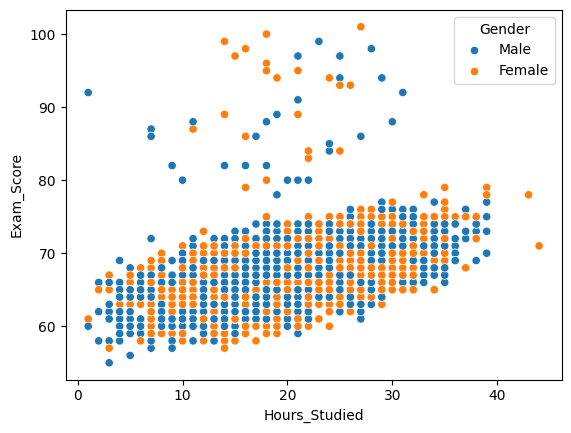

In [59]:
sns.scatterplot(data=df, x=df['Hours_Studied'], y=df['Exam_Score'], hue=df['Gender'])
plt.show()

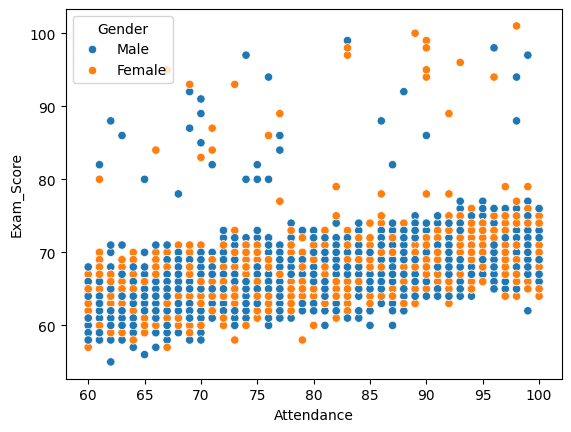

In [60]:
x = df['Attendance']
y = df['Exam_Score']
sns.scatterplot(data=df, x=x, y=y, hue=df['Gender'])
plt.show()

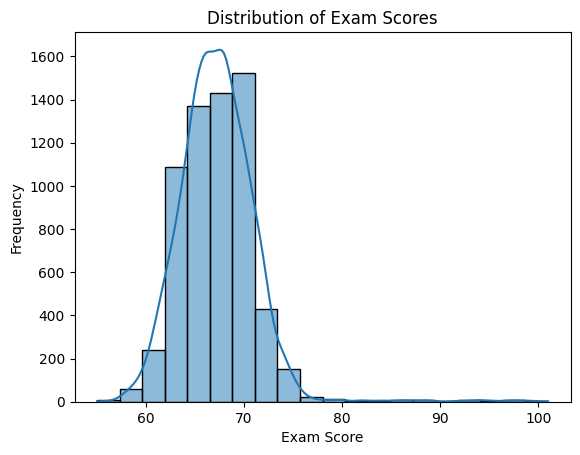

In [61]:
sns.histplot(data=df, x='Exam_Score', bins=20, kde=True)
plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Frequency')
plt.show()

# Column transformation using Label encoding

In [62]:
def col_transform(dataframe):
    dataframe['Parental_Involvement'] = dataframe['Parental_Involvement'].map({
        'Low': 1,
        'Medium': 2,
        'High': 3
    })
    
    dataframe['Access_to_Resources'] = dataframe['Access_to_Resources'].map({
        'Low': 1,
        'Medium': 2,
        'High': 3
    })
    
    dataframe['Motivation_Level'] = dataframe['Motivation_Level'].map({
        'Low': 1,
        'Medium': 2,
        'High': 3
    })
    
    dataframe['Extracurricular_Activities'] = dataframe['Extracurricular_Activities'].map({
        'Yes': 1,
        'No': 0
    })
    
    dataframe['Internet_Access'] = dataframe['Internet_Access'].map({
        'Yes': 1,
        'No': 0
    })
    
    dataframe['Family_Income'] = dataframe['Family_Income'].map({
        'Low': 1,
        'Medium': 2,
        'High': 3
    })
    
    dataframe['Teacher_Quality'] = dataframe['Teacher_Quality'].map({
        'Low': 1,
        'Medium': 2,
        'High': 3
    })
    
    dataframe['School_Type'] = dataframe['School_Type'].map({
        'Public': 1,
        'Private': 0
    })
    
    dataframe['Peer_Influence'] = dataframe['Peer_Influence'].map({
        'Positive': 1,
        'Neutral':0,
        'Negative':-1
    })
    
    dataframe['Learning_Disabilities'] = dataframe['Learning_Disabilities'].map({
        'Yes': 1,
        'No': 0
    })
    
    dataframe['Parental_Education_Level'] = dataframe['Parental_Education_Level'].map({
        'High School':1,
        'College':2,
        'Postgraduate':3
    })
    
    dataframe['Distance_from_Home'] = dataframe['Distance_from_Home'].map({
        'Near': 1,
        'Moderate': 2,
        'Far': 3
    })
    
    dataframe['Gender'] = dataframe['Gender'].map({
        'Male': 1,
        'Female': 0
    })

    return dataframe
    

In [63]:
df = col_transform(df)

In [64]:

df.info()

<class 'pandas.DataFrame'>
Index: 6378 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6378 non-null   int64
 1   Attendance                  6378 non-null   int64
 2   Parental_Involvement        6378 non-null   int64
 3   Access_to_Resources         6378 non-null   int64
 4   Extracurricular_Activities  6378 non-null   int64
 5   Sleep_Hours                 6378 non-null   int64
 6   Previous_Scores             6378 non-null   int64
 7   Motivation_Level            6378 non-null   int64
 8   Internet_Access             6378 non-null   int64
 9   Tutoring_Sessions           6378 non-null   int64
 10  Family_Income               6378 non-null   int64
 11  Teacher_Quality             6378 non-null   int64
 12  School_Type                 6378 non-null   int64
 13  Peer_Influence              6378 non-null   int64
 14  Physical_Activity       

In [65]:
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,1,3,0,7,73,1,1,0,1,2,1,1,3,0,1,1,1,67
1,19,64,1,2,0,8,59,1,1,2,2,2,1,-1,4,0,2,2,0,61
2,24,98,2,2,1,7,91,2,1,2,2,2,1,0,4,0,3,1,1,74
3,29,89,1,2,1,8,98,2,1,1,2,2,1,-1,4,0,1,2,1,71
4,19,92,2,2,1,6,65,2,1,3,2,3,1,0,4,0,2,1,0,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,3,2,0,7,76,2,1,1,3,2,1,1,2,0,1,1,0,68
6603,23,76,3,2,0,8,81,2,1,3,1,3,1,1,2,0,1,1,0,69
6604,20,90,2,1,1,6,65,1,1,3,1,2,1,-1,2,0,3,1,0,68
6605,10,86,3,3,1,6,91,3,1,2,1,2,0,1,3,0,1,3,0,68


<Axes: >

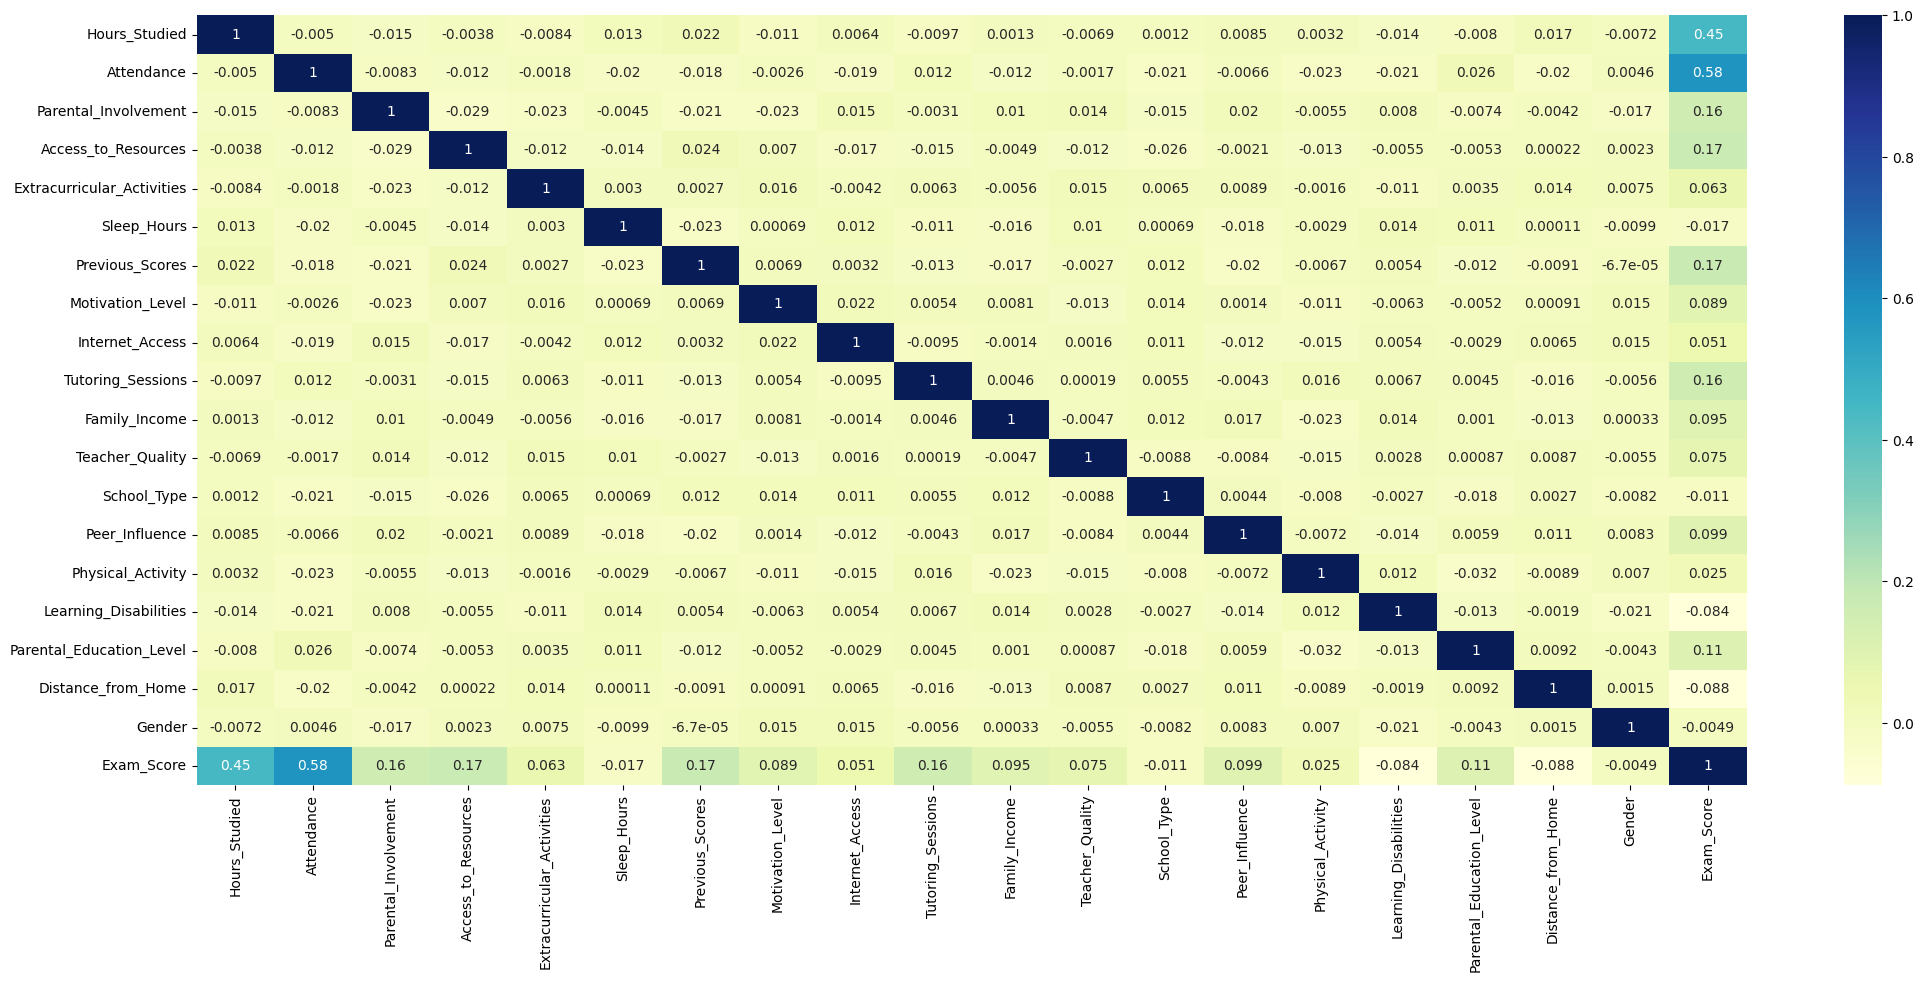

In [66]:
plt.figure(figsize=(25,10))
sns.heatmap(df.corr(), annot=True, cmap='YlGnBu')

# Splitting our dataset into features and target

In [67]:
x = df.drop(['Exam_Score'], axis=1)
y = df['Exam_Score']

# Splitting our dataset into training and testing

In [68]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=42)

In [69]:
print(x_train.isnull().sum())

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
dtype: int64


# scaling our dataset

In [70]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

In [71]:
#from sklearn.metrics import r2_score, mean_squared_error
#LR_y_pred =LR_model.predict(x_test_s)
#LR_score = r2_score(y_test, LR_y_pred)

#LR_test_rmse = np.sqrt(mean_squared_error(y_test, LR_y_pred))
#print('\n==================================')
#print(f'Linear Regression R2 Score: {LR_score}')
#print(f'Linear Regression  RMSE: {LR_test_rmse}')
#print('==================================')

In [72]:
x_train

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
6605,10,86,3,3,1,6,91,3,1,2,1,2,0,1,3,0,1,3,0
3221,25,70,1,3,0,8,73,3,1,1,1,1,1,-1,2,0,3,1,1
3112,18,87,1,1,0,8,57,2,0,3,3,3,1,1,4,0,1,1,1
4716,34,75,1,2,1,5,66,2,1,0,1,2,0,1,3,0,1,1,1
6547,15,94,2,2,1,6,77,1,1,3,3,3,0,0,4,0,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3904,30,70,3,1,0,6,84,3,1,2,2,2,1,1,3,0,3,1,1
5378,24,90,1,1,1,9,97,3,1,3,1,2,1,1,4,0,1,1,1
5415,24,65,1,3,1,7,52,2,1,1,3,2,1,0,1,0,3,2,0
5582,30,91,2,3,1,7,95,1,1,1,2,3,1,1,3,0,2,1,0


In [73]:
#from sklearn.model_selection import GridSearchCV

#grid_search = GridSearchCV(estimator = RF,
#                          param_grid=param_grid, 
#                          cv=5, n_jobs= -1,
#                          scoring='neg_mean_squared_error',error_score='raise')

#grid_search.fit(x_train_s, y_train)

In [74]:
#grid_search.best_score_

In [75]:
#grid_search.best_params_

# Using Hyperparameter tuning for Random Forest Regressor

In [ ]:
RF_model = RandomForestRegressor(random_state=42)

RF_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('model', RF_model)
])



RF_param_distributions = {
    'model__n_estimators': [300, 400, 500],
    'model__criterion': ['squared_error', 'absolute_error', 'poisson'],
    'model__min_samples_split': [5, 10, 15],
    'model__min_samples_leaf': [4, 6, 8],
    'model__max_depth': [10, 20, 30, None]
}

RF_random_search = RandomizedSearchCV(
    estimator=RF_pipeline,
    param_distributions=RF_param_distributions,
    n_iter=20,               
    cv=2,                   
    n_jobs=-1,               
    scoring='r2',
    random_state=42,         
    verbose=2               
)

RF_random_search.fit(x_train, y_train)

# 5. View results
print("Best Hyperparameters Found:")
print(RF_random_search.best_params_)

print("\nBest R2 Score:")
print(RF_random_search.best_score_)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


# Random Forest on Test date

In [ ]:

RF_y_pred = RF_random_search.predict(x_test)

RF_test_r2 = r2_score(y_test, RF_y_pred)
RF_test_rmse = np.sqrt(mean_squared_error(y_test, RF_y_pred))
print('\n==================================')
print(f'Random Forest R2 Score: {RF_test_r2}')
print(f'Random Forest RMSE: {RF_test_rmse}')
print('==================================')


Random Forest R2 Score: 0.6540545586520136
Random Forest RMSE: 2.3903514232530694


# Using Hyperparameter tuning for Decision Tree Regressor

In [ ]:
DT_model = DecisionTreeRegressor(random_state=42)
DT_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('model', DT_model)
])

dt_param_distributions = {
    'model__criterion': ['squared_error', 'absolute_error', 'poisson'],
    'model__min_samples_split': [5, 10, 15],
    'model__min_samples_leaf': [8, 10, 12],
    'model__max_depth': [ 30, 40, 50, None]
}

# 3. Set up RandomizedSearchCV
dt_random_search = RandomizedSearchCV(
    estimator=DT_pipeline,
    param_distributions=dt_param_distributions,
    n_iter=20,               
    cv=2,                   
    n_jobs=-1,               
    scoring='r2',
    random_state=42,         
    verbose=2 ,   
    error_score='raise'
)

# 4. Fit to your scaled training data
dt_random_search.fit(x_train, y_train)

# 5. View results
print("Best Hyperparameters Found:")
print(dt_random_search.best_params_)

print("\nBest R2 Score:")
print(dt_random_search.best_score_)

Fitting 2 folds for each of 20 candidates, totalling 40 fits
Best Hyperparameters Found:
{'model__min_samples_split': 5, 'model__min_samples_leaf': 8, 'model__max_depth': 40, 'model__criterion': 'absolute_error'}

Best R2 Score:
0.5323925286267002


# Decision Tree on Test data

In [ ]:
dt_y_pred = dt_random_search.predict(x_test)
dt_test_r2 = r2_score(y_test, dt_y_pred)
dt_test_rmse = np.sqrt(mean_squared_error(y_test, dt_y_pred))
print('\n==================================')
print(f'Decision Tree R2 Score: {dt_test_r2}')
print(f'Decision Tree RMSE: {dt_test_rmse}')
print('==================================')


Decision Tree R2 Score: 0.574645113960583
Decision Tree RMSE: 2.6505357199867747


# Using Hyperparameter tuning for XGBRegressor

In [ ]:
xgb_model = XGBRegressor(random_state=42)
xgb_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('model', xgb_model)
])
# 2. Define the parameter distributions/grid
xgb_param_distributions = {
    'model__n_estimators': [100, 200, 300],
    'model__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__colsample_bytree': [0.6, 0.8, 1],
    'model__subsample': [0.6, 0.8, 1],
    'model__max_depth': [10, 20, 30]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_distributions,
    n_iter=15,               
    cv=2,                    
    n_jobs=-1,              
    scoring='r2',
    random_state=42,         
    verbose=2   
)

# 4. Fit to your scaled training data
xgb_random_search.fit(x_train, y_train)

# 5. View results
print("Best Hyperparameters Found:")
print(xgb_random_search.best_params_)

print("\nBest R2 Score:")
print(xgb_random_search.best_score_)

Fitting 2 folds for each of 15 candidates, totalling 30 fits
Best Hyperparameters Found:
{'model__subsample': 0.6, 'model__n_estimators': 100, 'model__max_depth': 20, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}

Best R2 Score:
0.6352005898952484


# XGBRegressor on Test data

In [ ]:
xgb_y_pred = xgb_random_search.predict(x_test)

xgb_test_r2 = r2_score(y_test, xgb_y_pred)
xgb_test_rmse = np.sqrt(mean_squared_error(y_test, xgb_y_pred))
print('\n==================================')
print(f'XGBoost R2 Score: {xgb_test_r2}')
print(f'XGBoost RMSE: {xgb_test_rmse}')
print('==================================')


XGBoost R2 Score: 0.6450545191764832
XGBoost RMSE: 2.421245271582607


# Linear regression using data pipeline

In [ ]:
LR_model = LinearRegression()

LR_pipeline = Pipeline(steps=[
    ('scaler', MinMaxScaler()),
    ('model', LR_model)
])
LR_pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Hours_Studied','Attendance','Parental_Involvement',..., 'Parental_Education_Level','Distance_from_Home','Gender']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value


In [ ]:
pipe_y_pred = LR_pipeline.predict(x_test)

# Linear Regression on test data

In [ ]:
LR_score = r2_score(y_test, pipe_y_pred)

LR_test_rmse = np.sqrt(mean_squared_error(y_test, pipe_y_pred))
print('\n==================================')
print(f'Linear Regression R2 Score: {LR_score}')
print(f'Linear Regression  RMSE: {LR_test_rmse}')
print('==================================')


Linear Regression R2 Score: 0.7355247864850554
Linear Regression  RMSE: 2.090019974100911


# dumping our model using joblib

In [ ]:
import joblib 

joblib.dump(LR_pipeline, 'LR_Best_model.jb')

['Best_model.jb']

In [ ]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')

Hours_Studied                 12.6932
Attendance                     7.9512
Tutoring_Sessions              3.8742
Previous_Scores                2.3900
Access_to_Resources            2.0378
Parental_Involvement           1.9761
Physical_Activity              1.1778
Teacher_Quality                1.1094
Family_Income                  1.0992
Motivation_Level               1.0829
Parental_Education_Level       0.9956
Peer_Influence                 0.9930
Distance_from_Home             0.9486
Internet_Access                0.8718
Learning_Disabilities          0.8479
Extracurricular_Activities     0.5566
School_Type                    0.0633
Sleep_Hours                    0.0321
Gender                         0.0117
dtype: float64
Intercept: 49.613


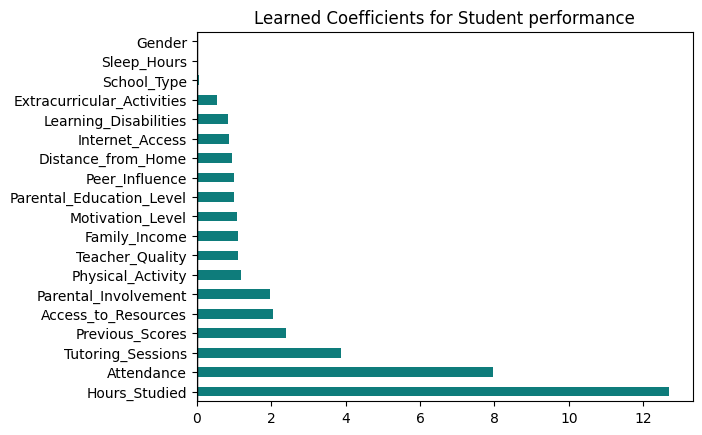

In [ ]:
model = LR_pipeline.named_steps['model']
importance = pd.Series(abs(model.coef_),
                       index=x_train.columns).sort_values(ascending=False)

print(importance.round(4))
print("Intercept:", round(model.intercept_, 4))

importance.plot(
    kind="barh",
    color=[
        "#0E7C7B" if c > 0 else "#C8553D"
        for c in importance
    ]
)

plt.title("Learned Coefficients for Student performance")
plt.axvline(0, color="black", lw=1)
plt.show()